# Predicting Blood–Brain Barrier Penetration from Molecular Graphs
**ENG 2440 Medical Imaging & AI in Healthcare — Assignment 3**

Zichen Zhao (25011189)

A molecule is a graph: atoms are nodes and bonds are edges. This notebook builds that graph for every
compound in the BBBP dataset, trains a small bond-aware graph neural network to predict whether a
compound is labeled as crossing the blood–brain barrier, and compares it with a Morgan-fingerprint
baseline under two ways of splitting the data. It is an educational experiment on a curated research
label, not a drug-development or clinical decision tool.

## 0. Setup
### 0.1 Configuration
Every setting used below lives in this one dictionary, so the whole experiment can be reproduced from it.

In [1]:
CONFIG = {
    # data
    "data_root": "data/MoleculeNet",
    "dataset": "BBBP",
    # splits
    "fractions": (0.70, 0.15, 0.15),     # train : validation : test
    "split_seed": 0,                     # one fixed seed for both split strategies
    # fingerprint baseline
    "fp_radius": 2,                      # ECFP4 convention: neighborhoods reach 2 bonds from each atom
    "fp_bits": 2048,
    "fp_grid": (0.01, 0.1, 1.0, 10.0),   # logistic-regression inverse regularization strength
    # graph neural network
    "hidden": 128,
    "layers": 3,                         # message-passing rounds
    "dropout": 0.3,
    "batch_size": 128,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 150,
    "patience": 30,                      # epochs without a better validation ROC-AUC before stopping
    "train_seeds": (0, 1, 2),            # three reported runs per split strategy
    # evaluation
    "n_boot": 2000,                      # bootstrap resamples for the 95% confidence intervals
}

### 0.2 Imports, device and seeds

In [2]:
import json
import time
import warnings
from pathlib import Path

# PyTorch Geometric still compiles some of its operators with torch.jit.script, which this version of
# torch deprecates. The warning is raised inside the library on import, there is nothing in this notebook
# to change in response to it, and it would otherwise be the first thing printed. Silenced for legibility.
warnings.filterwarnings("ignore", message=r".*torch\.jit\.script.*deprecated.*", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
import torch
import torch_geometric
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from IPython.display import display

from helpers import baseline, data, features, metrics, models
from helpers.plotting import (NEGATIVE, POSITIVE, chance_line, class_tag, confusion_panel, diagonal,
                              draw_graph, draw_molecule, figsize, finish, label_lines, method_style,
                              molecule_grid, molecule_panel, panel_label, place_text,
                              save_and_show, style_table, text_color, tint, wrap_smiles,
                              COOL_GREY, COOL_INK, INK, MUTED, PETROL, RED, RULE, SLATE,
                              LABEL_PT, TICK_PT)
from helpers.train import predict, set_seed, train_run

pd.set_option("display.width", 150)
TABLE_DIR = Path("outputs/tables")       # tables the report reads
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# The CPU is used deliberately. This model has 243k parameters and the dataset has under 2,000
# molecules, so the CPU is actually faster here than the Apple-silicon GPU (13 s against 20 s for 40
# epochs) and, unlike the GPU, it is exactly reproducible: scatter-add on a GPU accumulates messages in a
# non-deterministic order, so the same seed gives slightly different numbers on each run.
DEVICE = torch.device("cpu")
set_seed(CONFIG["split_seed"])
print(f"device: {DEVICE} | torch {torch.__version__} | torch-geometric {torch_geometric.__version__} "
      f"| rdkit {rdkit.__version__} | scikit-learn {sklearn.__version__} | numpy {np.__version__}")

device: cpu | torch 2.15.0 | torch-geometric 2.8.1 | rdkit 2025.03.6 | scikit-learn 1.9.1 | numpy 2.5.5


## A. The task and the dataset
### A.1 What goes in, what comes out

**Input.** One chemical compound, given as a SMILES string and converted to a molecular graph: each
heavy (non-hydrogen) atom is a node carrying nine categorical features, each bond is an edge carrying
three categorical features, and hydrogens stay implicit in the atoms' `num_hs` feature.

**Output.** One probability for the whole molecule — the estimated chance that the compound carries the
positive BBBP label. A single decision threshold, fixed on validation data, turns that probability into
a predicted class. The model makes one prediction per molecule, never one per atom.

**Unit of analysis.** The molecule. Atoms and bonds are the parts a prediction is built from, but every
metric in this notebook counts molecules, and the splits below divide molecules, never atoms.

**Intended technical use.** A screening aid in early computational chemistry: given a list of candidate
compounds, rank them by predicted penetration so that laboratory effort can be spent on the more
promising ones. It is not a clinical tool and not evidence about any individual patient.

**What the labels mean.** `p_np = 1` (positive) marks a compound that the curated literature source
records as penetrating the blood–brain barrier; `p_np = 0` (negative) marks one recorded as
non-penetrating. The label is a research annotation collected from published permeability studies, not a
measurement made for this work. It says what the literature concluded about a compound, which is not the
same as what would happen in a given patient, and it carries whatever disagreement and reporting bias
the source studies had.

### A.2 Loading the dataset and auditing it
The loader downloads BBBP and turns every SMILES string into a graph. It silently drops strings RDKit
cannot parse, so the distributed CSV is read as well — that is the only way to count what was lost.

In [3]:
dataset = MoleculeNet(root=CONFIG["data_root"], name=CONFIG["dataset"])
raw_csv = Path(CONFIG["data_root"]) / "bbbp" / "raw" / "BBBP.csv"
raw = data.audit_raw_csv(raw_csv)

print(f"{dataset}")
print(f"distributed CSV      : {raw['records']} records, columns {raw['columns']}")
print(f"missing labels       : {raw['missing_labels']}   non-binary labels: {raw['non_binary_labels']}")
print(f"SMILES RDKit rejects : {raw['unparseable_smiles']}  -> {raw['valid_graphs']} valid molecules")
print(f"graphs the loader returns: {len(dataset)}")
assert len(dataset) == raw["valid_graphs"], "the loader kept a different set than RDKit accepts"

BBBP(2039)
distributed CSV      : 2050 records, columns ['num', 'name', 'p_np', 'smiles']
missing labels       : 0   non-binary labels: 0
SMILES RDKit rejects : 11  -> 2039 valid molecules
graphs the loader returns: 2039


Every label is a finite 0 or 1 and no graph is empty, so the only records lost so far are the
unparseable SMILES. Three quarters of the molecules are positive, which the loss and the decision
threshold both have to account for later.

In [4]:
labels_all = np.array([int(g.y.view(-1)[0]) for g in dataset])
atom_counts = np.array([g.num_nodes for g in dataset])
bond_counts = np.array([g.edge_index.shape[1] // 2 for g in dataset])
print(f"graphs with no atom : {(atom_counts == 0).sum()}   graphs with no bond: {(bond_counts == 0).sum()}")
print(f"non-finite labels   : {(~np.isfinite(labels_all)).sum()}")
print(f"class counts        : negative {int((labels_all == 0).sum())}, positive {int((labels_all == 1).sum())}")
print(f"class proportions   : negative {(labels_all == 0).mean():.3f}, positive {labels_all.mean():.3f}")

graphs with no atom : 0   graphs with no bond: 0
non-finite labels   : 0
class counts        : negative 479, positive 1560
class proportions   : negative 0.235, positive 0.765


The same compound can be written as several different SMILES strings, so duplicates are only visible
after canonicalization: RDKit rewrites every molecule in one standard form, and two records describing
the same compound then become the same string.

In [5]:
records, summary = data.clean(dataset)
print(f"molecules loaded                      : {summary['loaded']}")
print(f"invalid or empty graphs               : {summary['invalid_or_empty']}")
print(f"unique canonical molecules            : {summary['unique_canonical']}")
print(f"molecules appearing more than once    : {summary['molecules_seen_more_than_once']}"
      f"  (= {summary['duplicate_records']} duplicate records)")
print(f"canonical molecules with both labels  : {summary['conflicting_groups']}"
      f"  (= {summary['records_in_conflicting_groups']} records)")

for example in data.duplicate_examples(records, n=3):
    agreement = "same label" if len(example["labels"]) == 1 else "CONFLICTING labels"
    print(f"\n  {example['canonical']}")
    print(f"    {example['records']} records, labels {example['labels']} -> {agreement}")
    for original in example["original_smiles"]:
        print(f"      written as: {original}")

molecules loaded                      : 2039
invalid or empty graphs               : 0
unique canonical molecules            : 1975
molecules appearing more than once    : 60  (= 64 duplicate records)
canonical molecules with both labels  : 10  (= 20 records)

  CNCCc1ccccn1
    3 records, labels [1] -> same label
      written as: n(ccc1)c(c1)CCNC
      written as: c1c(nccc1)CCNC
      written as: c1cc(CCNC)ncc1

  NCCc1cn2ccccc2n1
    3 records, labels [0] -> same label
      written as: c1cccn2c1nc(c2)CCN
      written as: NCCc1cn2c(n1)cccc2
      written as: c1c(nc2n1cccc2)CCN

  CN(C)CCc1ccccn1
    3 records, labels [1] -> same label
      written as: n(ccc1)c(c1)CCN(C)C
      written as: c1c(nccc1)CCN(C)C
      written as: c1cc(CCN(C)C)ncc1


**The cleaning rule.** Invalid and empty graphs are dropped. When several records share a canonical
molecule and agree on the label, one record is kept. When they disagree, every record in that group is
removed: there is no way to tell which label is right, and either choice would put a wrong label into
training or into a test set. Both splits are built only after this step.

In [6]:
kept = records[records["kept"]].reset_index(drop=True)
graph_index = kept["index"].to_numpy()               # positions in the PyG dataset, after cleaning
canonical_smiles = kept["canonical"].tolist()
labels = kept["y"].to_numpy()
n_molecules = len(kept)

print(f"after cleaning : {n_molecules} molecules "
      f"({summary['loaded'] - n_molecules} removed: {summary['invalid_or_empty']} invalid, "
      f"{summary['duplicate_records'] - summary['records_in_conflicting_groups'] + summary['conflicting_groups']} "
      f"duplicate, {summary['records_in_conflicting_groups']} in conflicting groups)")
print(f"class balance  : negative {int((labels == 0).sum())} ({(labels == 0).mean():.3f}), "
      f"positive {int(labels.sum())} ({labels.mean():.3f})")
assert len(set(canonical_smiles)) == n_molecules, "a canonical molecule survived twice"

pd.DataFrame([{"stage": "distributed CSV", "molecules": raw["records"]},
              {"stage": "RDKit-parseable", "molecules": raw["valid_graphs"]},
              {"stage": "after removing duplicates and conflicts", "molecules": n_molecules}]
             ).to_csv(TABLE_DIR / "cleaning.csv", index=False)

after cleaning : 1965 molecules (74 removed: 0 invalid, 54 duplicate, 20 in conflicting groups)
class balance  : negative 465 (0.237), positive 1500 (0.763)


### A.3 What the molecules look like
Six structures, three from each class. To avoid picking convenient examples, the molecules are chosen by
a fixed rule: within each class, the compounds at the 25th, 50th and 75th percentile of atom count.

PASS A_molecules: 0 errors, 0 warnings, 6 taste notes -> figures/_preview/A_molecules.png
  [taste] crowded: 'C[S+](CC[C@H](N)C(=O)[O-])C[C@H]1O
[C@@H' and 'non-penetrating' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] crowded: 'C[C@]12CCC(=O)C=C1CC[C@@H]1[C@@H]2CC
[C@' and 'C/C=C/C1=C(C(=O)O)N2C(=O)[C@@H](NC(=O
)[' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] crowded: 'C/C=C/C1=C(C(=O)O)N2C(=O)[C@@H](NC(=O
)[' and 'CN(C)[C@@H]1C(=O)/C(=C(\N)O)C(=O)
[C@@]2' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'penetrating' is too light to read; use text_color()
  [taste] contrast: 'penetrating' is too light to read; use text_color()
  [taste] contrast: 'penetrating' is too light to read; use text_color()


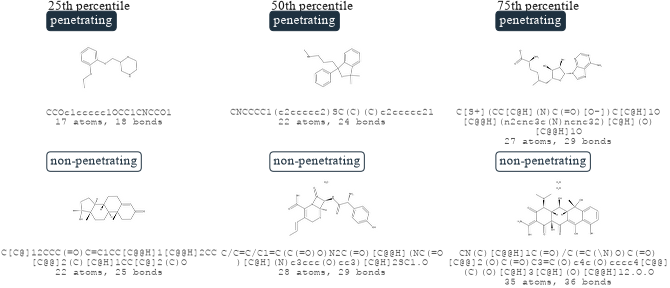

  penetrating      p_np=1  CCOc1ccccc1OCC1CNCCO1
  penetrating      p_np=1  CNCCCC1(c2ccccc2)SC(C)(C)c2ccccc21
  penetrating      p_np=1  C[S+](CC[C@H](N)C(=O)[O-])C[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1O
  non-penetrating  p_np=0  C[C@]12CCC(=O)C=C1CC[C@@H]1[C@@H]2CC[C@@]2(C)[C@H]1CC[C@]2(C)O
  non-penetrating  p_np=0  C/C=C/C1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)[C@H](N)c3ccc(O)cc3)[C@H]2SC1.O
  non-penetrating  p_np=0  CN(C)[C@@H]1C(=O)/C(=C(\N)O)C(=O)[C@@]2(O)C(=O)C3=C(O)c4c(O)cccc4[C@@](C)(O)[C@H]3[C@H](O)[C@@H]12.O.O


In [7]:
chosen = []
for label in (1, 0):
    pool = kept[kept["y"] == label].sort_values("n_atoms")
    positions = [int(q * (len(pool) - 1)) for q in (0.25, 0.50, 0.75)]
    chosen += [pool.iloc[p] for p in positions]

fig = plt.figure(figsize=figsize("full", aspect=0.44))
molecule_grid(fig, [{"smiles": r["canonical"], "label": r["y"],
                     "caption": f"{wrap_smiles(r['canonical'], 37)}\n{r['n_atoms']} atoms, {r['n_bonds']} bonds"}
                    for r in chosen], ncols=3, caption_pt=TICK_PT - 2, tag_ratio=0.22, caption_ratio=0.40,
              bond_length=104,
              col_headers=["25th percentile", "50th percentile", "75th percentile"])
fig.get_layout_engine().set(hspace=0.06, wspace=0.05)
save_and_show(fig, "A_molecules", width="full")

for row in chosen:
    print(f"  {'penetrating    ' if row['y'] == 1 else 'non-penetrating'}  p_np={row['y']}  {row['canonical']}")

### A.4 How big the graphs are, and what one graph holds
Molecule size varies over an order of magnitude, which is why the model pools atom vectors into a
fixed-length molecule vector instead of assuming a fixed number of atoms.

quantity,min,25%,median,75%,max,mean
atoms per molecule,2,18.0,23.0,29.0,132,24.2
bonds per molecule,1,19.0,25.0,31.0,145,26.1


PASS A_sizes: 0 errors, 0 warnings, 2 taste notes -> figures/_preview/A_sizes.png
  [taste] contrast: 'non-penetrating' is too light to read; use text_color()
  [taste] band: uncertainty band alpha 1.00; keep bands quiet (~0.15)


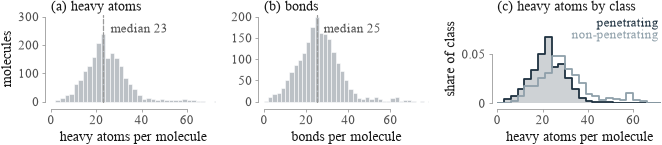

size panels clipped at the 99.5th percentile: atoms at 73 (10 molecules beyond it, largest 132), bonds at 78 (10 beyond it, largest 145)


In [8]:
atoms_kept, bonds_kept = kept["n_atoms"].to_numpy(), kept["n_bonds"].to_numpy()
size_table = pd.DataFrame({
    "quantity": ["atoms per molecule", "bonds per molecule"],
    "min": [atoms_kept.min(), bonds_kept.min()],
    "25%": [np.percentile(atoms_kept, 25), np.percentile(bonds_kept, 25)],
    "median": [np.median(atoms_kept), np.median(bonds_kept)],
    "75%": [np.percentile(atoms_kept, 75), np.percentile(bonds_kept, 75)],
    "max": [atoms_kept.max(), bonds_kept.max()],
    "mean": [atoms_kept.mean(), bonds_kept.mean()],
})
display(style_table(size_table, precision=1, caption=f"Graph size over {n_molecules} cleaned molecules"))
size_table.to_csv(TABLE_DIR / "graph_sizes.csv", index=False)

# aspect is per panel and figsize divides it by ncols, so three panels need three times the number
# that one panel would take. At 0.44 the whole figure came out one inch tall.
fig, axes = plt.subplots(1, 3, figsize=figsize("full", aspect=0.68, ncols=3))
clip = {name: float(np.percentile(v, 99.5)) for name, v in (("atoms", atoms_kept), ("bonds", bonds_kept))}
for ax, values, name in zip(axes, (atoms_kept, bonds_kept), ("atoms", "bonds")):
    ax.hist(values, bins=np.arange(0, values.max() + 3, 2), color=tint(COOL_INK, 0.30),
            edgecolor="white", linewidth=0.4)
    median = float(np.median(values))
    # Neutral gray: these bars describe the dataset, and the model hues must keep meaning a model.
    # zorder above the bars, or the reference line disappears behind the tallest ones.
    ax.axvline(median, color=RULE, lw=0.9, ls="--", zorder=6)
    ax.set_xlabel(f"heavy {name} per molecule" if name == "atoms" else f"{name} per molecule")
    ax.set_ylabel("molecules" if name == "atoms" else "")
    finish(ax, nticks=4, xlim=(0, clip[name]))
    place_text(ax, f"median {median:.0f}", prefer=(median / clip[name] + 0.04, 0.92), color=MUTED)

# Panel (c) answers the question panels (a) and (b) raise: is the label just a size cue? Counts are
# turned into densities because the classes are 76:24, so raw heights would compare nothing.
ax = axes[2]
bins = np.arange(0, clip["atoms"] + 3, 3)
# Filled for penetrating, outlined for non-penetrating: the same way the class is shown on the tags in
# Figure 1, and it keeps a gray dashed line meaning only "reference line".
for label, filled, line in ((1, True, COOL_INK), (0, False, COOL_GREY)):
    density, edges = np.histogram(kept.loc[kept["y"] == label, "n_atoms"], bins=bins, density=True)
    if filled:
        ax.fill_between(edges[:-1], density, step="post", color=tint(COOL_INK, 0.22), lw=0)
    # Each curve is drawn in the color its own label is written in, so the labels sit directly on
    # their series instead of relying on the reader matching fill to text.
    ax.step(edges[:-1], density, where="post", color=line, lw=1.3)
ax.set_xlabel("heavy atoms per molecule")
ax.set_ylabel("share of class")
# Reserve a band above the tallest bin and label inside it. Hunting for a gap between the two curves
# kept failing because "non-penetrating" is wide enough to reach back over the distribution's shoulder.
peak = max(np.histogram(kept.loc[kept["y"] == lab, "n_atoms"], bins=bins, density=True)[0].max()
           for lab in (0, 1))
finish(ax, nticks=4, xlim=(0, clip["atoms"]), ylim=(0, peak * 1.34))
place_text(ax, "penetrating", prefer=(0.97, 0.97), color=COOL_INK)
place_text(ax, "non-penetrating", prefer=(0.97, 0.82), color=COOL_GREY)

for ax, panel, name in zip(axes, "abc", ("heavy atoms", "bonds", "heavy atoms by class")):
    panel_label(ax, panel, name)
fig.get_layout_engine().set(wspace=0.07)
save_and_show(fig, "A_sizes", width="full")

clipped = {name: int((v > clip[name]).sum()) for name, v in (("atoms", atoms_kept), ("bonds", bonds_kept))}
print(f"size panels clipped at the 99.5th percentile: atoms at {clip['atoms']:.0f} "
      f"({clipped['atoms']} molecules beyond it, largest {atoms_kept.max()}), "
      f"bonds at {clip['bonds']:.0f} ({clipped['bonds']} beyond it, largest {bonds_kept.max()})")

One graph, printed exactly as PyTorch Geometric stores it. `x` holds one row per atom and nine feature
columns; `edge_index` lists the two endpoints of every directed edge, so each chemical bond appears
twice (once in each direction); `edge_attr` carries three features for each of those directed edges;
`y` is the molecule's label and `smiles` the string it was built from.

In [9]:
example = dataset[int(graph_index[0])]
print(f"graph           : {example}")
print(f"x.shape         : {tuple(example.x.shape)}   (atoms x atom features, dtype {example.x.dtype})")
print(f"edge_index.shape: {tuple(example.edge_index.shape)}   (2 x directed edges = 2 x {example.edge_index.shape[1] // 2} bonds)")
print(f"edge_attr.shape : {tuple(example.edge_attr.shape)}   (directed edges x bond features)")
print(f"y               : {example.y}  -> label {int(example.y.view(-1)[0])}")
print(f"smiles          : {example.smiles}")
print(f"\nfirst three atom rows:\n{example.x[:3]}")
print(f"first three edge rows:\n{example.edge_attr[:3]}")

graph           : Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])
x.shape         : (20, 9)   (atoms x atom features, dtype torch.int64)
edge_index.shape: (2, 40)   (2 x directed edges = 2 x 20 bonds)
edge_attr.shape : (40, 3)   (directed edges x bond features)
y               : tensor([[1.]])  -> label 1
smiles          : [Cl].CC(C)NCC(O)COc1cccc2ccccc12

first three atom rows:
tensor([[17,  0,  0,  5,  0,  1,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
        [ 6,  0,  4,  5,  1,  0,  4,  0,  0]])
first three edge rows:
tensor([[1, 0, 0],
        [1, 0, 0],
        [1, 0, 0]])


## B. Building and batching molecular graphs
### B.1 What the graph stores, and what the numbers in it mean

PyTorch Geometric turns a SMILES string into four arrays. `x` has one row per heavy atom and nine
columns; `edge_index` has two rows and one column per *directed* edge, listing the atoms each edge
joins; `edge_attr` has one row per directed edge and three columns; `y` holds the molecule's label.
Every chemical bond becomes two directed edges, one in each direction, so a message can travel both
ways during message passing.

Every column of `x` and `edge_attr` is a **category code**, not a quantity: the integer is the position
of that atom's or bond's category in a fixed list. Code 7 in the element column means nitrogen, not
"seven of something", and aromatic bonds are code 12 while triple bonds are code 3 — arithmetic on
those numbers is meaningless. The tables below name every column and show which categories BBBP
actually uses.

In [10]:
atom_features = features.describe_atom_features(dataset)
bond_features = features.describe_bond_features(dataset)
display(style_table(atom_features, caption="Atom feature columns in x (9 columns)"))
display(style_table(bond_features, caption="Bond feature columns in edge_attr (3 columns)"))
atom_features.to_csv(TABLE_DIR / "atom_features.csv", index=False)
bond_features.to_csv(TABLE_DIR / "bond_features.csv", index=False)

column,feature,meaning,vocabulary,codes seen,categories seen
0,atomic_num,chemical element (code = atomic number),119,13,"1, 5, 6, 7, ..."
1,chirality,local three-dimensional arrangement at the atom,9,3,"CHI_UNSPECIFIED, CHI_TETRAHEDRAL_CW, CHI_TETRAHEDRAL_CCW"
2,degree,number of bonded neighbors in the graph,11,5,"0, 1, 2, 3, ..."
3,formal_charge,assigned charge (code 5 is neutral),12,4,"-1, 0, 1, 2"
4,num_hs,"attached hydrogens, which the graph does not store as nodes",9,4,"0, 1, 2, 3"
5,num_radical_electrons,unpaired electrons,5,2,"0, 1"
6,hybridization,"orbital hybridization (sp, sp2, sp3, ...)",8,4,"S, SP, SP2, SP3"
7,is_aromatic,atom belongs to an aromatic ring,2,2,"False, True"
8,is_in_ring,atom belongs to any ring,2,2,"False, True"


column,feature,meaning,vocabulary,codes seen,categories seen
0,bond_type,"single, double, triple or aromatic bond",22,4,"SINGLE, DOUBLE, TRIPLE, AROMATIC"
1,stereo,"double-bond stereochemistry (none, Z, E, ...)",6,3,"STEREONONE, STEREOZ, STEREOE"
2,is_conjugated,bond is part of a conjugated system,2,2,"False, True"


**How the codes are encoded.** Each column gets its own **trainable embedding table**: the code is
looked up and returns a learned vector of length `hidden`, and the nine atom vectors (or three bond
vectors) are summed into one vector per atom (or per bond). Embeddings are used rather than one-hot
vectors for two reasons. First, the element column alone has 119 categories, so one-hot encoding would
produce a wide, almost-empty input in which most columns are never on. Second, an embedding lets the
model learn that two categories behave alike — chlorine and bromine, for example — instead of forcing
every category to stay equally far from every other, which is what one-hot does. Either choice keeps
the codes categorical; neither lets the raw integer act as a number.

In [11]:
encoder = models.CategoryEncoder(features.ATOM_VOCAB, CONFIG["hidden"])
example_codes = dataset[int(graph_index[0])].x
print(f"atom codes in          : {tuple(example_codes.shape)}  (atoms x 9 category columns)")
print(f"embedded atom vectors  : {tuple(encoder(example_codes).shape)}  (atoms x {CONFIG['hidden']})")
print(f"embedding tables       : {len(features.ATOM_VOCAB)} atom tables with sizes {features.ATOM_VOCAB}")
print(f"                         {len(features.BOND_VOCAB)} bond tables with sizes {features.BOND_VOCAB}")

atom codes in          : (20, 9)  (atoms x 9 category columns)
embedded atom vectors  : (20, 128)  (atoms x 128)
embedding tables       : 9 atom tables with sizes [119, 9, 11, 12, 9, 5, 8, 2, 2]
                         3 bond tables with sizes [22, 6, 2]


### B.2 The same molecule drawn two ways
The molecule shown is the one whose atom count is closest to 14 — small enough for every node to be
labeled, large enough to contain a ring, a double bond and more than one element.

PASS B_views: 0 errors, 1 warnings, 0 taste notes -> figures/_preview/B_views.png
  [warn] annotation: 'aromatic' sits outside its axes


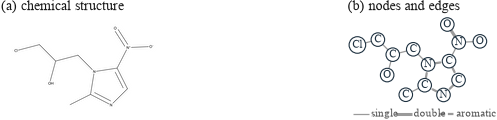

molecule : Cc1ncc([N+](=O)[O-])n1CC(O)CCl
label    : 1 (penetrating)
atoms    : 14 -> 14 nodes
bonds    : 14 -> 28 directed edges (each bond stored twice)


In [12]:
pick = kept.iloc[int(np.argmin(np.abs(kept["n_atoms"] - 14)))]
example_graph = dataset[int(pick["index"])]

fig, axes = plt.subplots(1, 2, figsize=figsize("full", aspect=0.38, ncols=2))
draw_molecule(axes[0], pick["canonical"])
draw_graph(axes[1], pick["canonical"], bond_key=True)
for ax, panel, title in zip(axes, "ab", ("chemical structure", "nodes and edges")):
    ax.set_xticks([]); ax.set_yticks([])
    panel_label(ax, panel, title)
save_and_show(fig, "B_views", width="full")

print(f"molecule : {pick['canonical']}")
print(f"label    : {pick['y']} ({'penetrating' if pick['y'] == 1 else 'non-penetrating'})")
print(f"atoms    : {pick['n_atoms']} -> {pick['n_atoms']} nodes")
print(f"bonds    : {pick['n_bonds']} -> {example_graph.edge_index.shape[1]} directed edges "
      f"(each bond stored twice)")

**How the two views line up.** Each atom in panel (a) is one circle in panel (b), drawn at the same
position, and each bond drawn between two atoms is one line between the matching circles. The views
differ in what they make explicit. The chemical drawing hides carbons at the line junctions and hides
hydrogens completely; the graph draws every heavy atom as a node and keeps hydrogens only as the
`num_hs` count inside that node's feature row. Bond order, which the drawing shows as a second line,
is a category code on the edge — drawn here as line weight, with aromatic bonds dashed. The model sees
panel (b): a set of nodes, a list of which pairs are joined, and a feature row for each.

### B.3 Batching many molecules at once
Molecules have different numbers of atoms, so they cannot be stacked like fixed-size images. PyTorch
Geometric instead joins a batch into one large graph with no edges between the molecules, and records
which molecule each atom came from in a `batch` vector. Pooling then averages atom vectors within each
molecule, so the batch still produces one prediction per molecule.

In [13]:
preview_loader = DataLoader([dataset[int(i)] for i in graph_index[:512]],
                            batch_size=CONFIG["batch_size"], shuffle=False)
one_batch = next(iter(preview_loader))
print(f"batch                : {one_batch}")
print(f"x.shape              : {tuple(one_batch.x.shape)}   "
      f"(all {one_batch.num_nodes} atoms of the {one_batch.num_graphs} molecules, stacked)")
print(f"edge_index.shape     : {tuple(one_batch.edge_index.shape)}   "
      f"(2 x {one_batch.edge_index.shape[1]} directed edges; indices point into the stacked atoms)")
print(f"edge_attr.shape      : {tuple(one_batch.edge_attr.shape)}   (one feature row per directed edge)")
print(f"batch.shape          : {tuple(one_batch.batch.shape)}   "
      f"(one entry per atom, values 0..{int(one_batch.batch.max())})")
print(f"y.shape              : {tuple(one_batch.y.shape)}   (one label per molecule)")
print(f"atoms per molecule   : min {int(one_batch.batch.bincount().min())}, "
      f"max {int(one_batch.batch.bincount().max())}")

batch                : DataBatch(x=[2957, 9], edge_index=[2, 6358], edge_attr=[6358, 3], smiles=[128], y=[128, 1], batch=[2957], ptr=[129])
x.shape              : (2957, 9)   (all 2957 atoms of the 128 molecules, stacked)
edge_index.shape     : (2, 6358)   (2 x 6358 directed edges; indices point into the stacked atoms)
edge_attr.shape      : (6358, 3)   (one feature row per directed edge)
batch.shape          : (2957,)   (one entry per atom, values 0..127)
y.shape              : (128, 1)   (one label per molecule)
atoms per molecule   : min 3, max 60


### B.4 Checks that nothing is lost or malformed
These assertions run on every batch of the whole cleaned dataset, so a silent failure cannot reach
training.

In [14]:
check_loader = DataLoader([dataset[int(i)] for i in graph_index], batch_size=CONFIG["batch_size"],
                          shuffle=False)
molecules_seen, atoms_seen, labels_seen = 0, 0, []
for batch in check_loader:
    y = batch.y.view(-1)
    assert torch.isfinite(y).all(), "a label is NaN or infinite"
    assert set(y.unique().tolist()) <= {0.0, 1.0}, "a label is neither 0 nor 1"
    assert y.numel() == batch.num_graphs, "label count does not match the number of graphs in the batch"
    counts = batch.batch.bincount(minlength=batch.num_graphs)
    assert (counts > 0).all(), "a graph in this batch has no atom"
    assert int(batch.edge_index.max()) < batch.num_nodes, "an edge points outside the batch"
    assert batch.edge_attr.shape[0] == batch.edge_index.shape[1], "edge features and edges disagree"
    molecules_seen += batch.num_graphs
    atoms_seen += batch.num_nodes
    labels_seen.append(y)

labels_seen = torch.cat(labels_seen).numpy()
assert molecules_seen == n_molecules, "batching lost or duplicated a molecule"
assert atoms_seen == int(kept["n_atoms"].sum()), "batching lost atoms"
assert np.array_equal(labels_seen, labels.astype(float)), "batch labels are in the wrong order"
print(f"all {len(check_loader)} batches pass:")
print(f"  molecules in = {n_molecules}, molecules out = {molecules_seen}")
print(f"  atoms in     = {int(kept['n_atoms'].sum())}, atoms out     = {atoms_seen}")
print(f"  every label finite and in {{0, 1}}, every graph has at least one atom,")
print(f"  labels come back in dataset order")

all 16 batches pass:
  molecules in = 1965, molecules out = 1965
  atoms in     = 47599, atoms out     = 47599
  every label finite and in {0, 1}, every graph has at least one atom,
  labels come back in dataset order


## C. Two ways of splitting the data
### C.1 A stratified random split and a Bemis–Murcko scaffold split

Both strategies divide the same 1,965 cleaned molecules into 70% training, 15% validation and 15% test,
using one fixed seed so that every run below sees exactly the same subsets.

The **stratified random split** shuffles each class separately and takes 70:15:15 from each, so the
proportion of penetrating compounds is the same in all three subsets.

The **scaffold split** first reduces every molecule to its Bemis–Murcko scaffold — the ring systems plus
the linkers joining them, with all side chains removed — and then assigns whole scaffold groups, largest
first, until each subset is full. Molecules sharing a scaffold therefore always land in the same subset,
and the validation and test sets are built from scaffolds the model has never seen.

**Molecules with no ring system** have an empty Bemis–Murcko scaffold. There are 95 of them, and they
are treated as one group under the empty-scaffold key, which keeps the rule "same scaffold, same subset"
true for them too. No molecule has an invalid scaffold at this point, because the cleaning step already
removed everything RDKit could not parse.

In [15]:
scaffolds, scaffold_stats = data.scaffold_table(canonical_smiles)
print(f"molecules                         : {scaffold_stats['molecules']}")
print(f"unique Bemis-Murcko scaffolds     : {scaffold_stats['unique_scaffolds']}")
print(f"molecules with no ring system     : {scaffold_stats['acyclic_molecules']} (empty scaffold)")
print(f"scaffolds holding a single molecule: {scaffold_stats['scaffolds_with_one_molecule']}")
print(f"largest scaffold group            : {scaffold_stats['largest_scaffold_size']} molecules")
assert all(s is not None for s in scaffolds), "a cleaned molecule has no computable scaffold"

splits = {
    "random": data.stratified_random_split(labels, CONFIG["fractions"], seed=CONFIG["split_seed"]),
    "scaffold": data.scaffold_split(scaffolds, CONFIG["fractions"], seed=CONFIG["split_seed"]),
}

molecules                         : 1965
unique Bemis-Murcko scaffolds     : 1020
molecules with no ring system     : 95 (empty scaffold)
scaffolds holding a single molecule: 777
largest scaffold group            : 128 molecules


### C.2 Verifying both splits
Each split must cover every molecule exactly once, and no canonical molecule may appear in two subsets.
The scaffold split must additionally keep the three scaffold sets disjoint.

In [16]:
for name, parts in splits.items():
    checks = data.verify_split(parts, canonical_smiles, n_molecules,
                               scaffolds=scaffolds if name == "scaffold" else None)
    print(f"{name:9s} split: " + ", ".join(f"{k} = {v}" for k, v in checks.items()
                                           if isinstance(v, bool)))
    if "unique_scaffolds_per_subset" in checks:
        print(f"           unique scaffolds per subset: {checks['unique_scaffolds_per_subset']}")

random    split: covers_every_molecule = True, pairwise_disjoint_indices = True, no_shared_canonical_smiles = True
scaffold  split: covers_every_molecule = True, pairwise_disjoint_indices = True, no_shared_canonical_smiles = True, disjoint_scaffolds = True
           unique scaffolds per subset: {'train': 430, 'validation': 295, 'test': 295}


### C.3 What each subset contains
The random split holds the class balance almost exactly, which is what stratifying is for. The scaffold
split has no mechanism to control the balance — it moves whole scaffold families at a time — yet the
proportion of penetrating compounds still lands close to the overall 0.76 in every subset. So the
difficulty the scaffold split adds does not come from a shifted class balance; it comes from the
chemistry, which the next panel measures directly.

In [17]:
summaries = []
for name, parts in splits.items():
    table = data.split_summary(parts, labels, scaffolds=scaffolds if name == "scaffold" else None)
    table.insert(0, "split", name)
    summaries.append(table)
    display(style_table(table, caption=f"{name} split"))
split_table = pd.concat(summaries, ignore_index=True)
split_table.to_csv(TABLE_DIR / "splits.csv", index=False)

split,subset,molecules,positives,positive_proportion
random,train,1376,1050,0.763
random,validation,295,225,0.763
random,test,294,225,0.765


split,subset,molecules,positives,positive_proportion,unique_scaffolds
scaffold,train,1375,1054,0.767,430
scaffold,validation,295,227,0.769,295
scaffold,test,295,219,0.742,295


### C.4 Why a random split flatters a model
A random split decides where a molecule goes without looking at what the molecule is, so two compounds
from the same chemical series — a drug and its close analog, differing by one methyl group — can end
up one in training and one in test. Predicting the test molecule then needs no generalization to new
chemistry: a model that has memorized the training analog already has most of the answer. The score
that follows describes how well the model interpolates inside families it has seen, which is not the
question a screening tool has to answer.

This is measurable. For every test molecule, the panel below shows the Tanimoto similarity to its most
similar training molecule. Under the random split a large share of test molecules have a very close
training neighbor; under the scaffold split the whole distribution moves down, because molecules
sharing a scaffold were forced to stay together.

In [18]:
fingerprint_bits = baseline.fingerprints(canonical_smiles, CONFIG["fp_radius"], CONFIG["fp_bits"])
print(f"Morgan fingerprints: {fingerprint_bits.shape[0]} molecules x {fingerprint_bits.shape[1]} bits "
      f"(radius {CONFIG['fp_radius']}), mean bits set {fingerprint_bits.sum(1).mean():.1f}")

nearest = {}
for name, parts in splits.items():
    train_bits = fingerprint_bits[parts[0]].astype(np.float32)
    similarity = [baseline.nearest_training_molecule(fingerprint_bits[i].astype(np.float32), train_bits)[1]
                  for i in parts[2]]
    nearest[name] = np.array(similarity)
    print(f"{name:9s} split: test molecules with a training neighbor above Tanimoto 0.6: "
          f"{(nearest[name] > 0.6).mean():.3f}   median nearest similarity {np.median(nearest[name]):.3f}")

Morgan fingerprints: 1965 molecules x 2048 bits (radius 2), mean bits set 43.0


random    split: test molecules with a training neighbor above Tanimoto 0.6: 0.439   median nearest similarity 0.566


scaffold  split: test molecules with a training neighbor above Tanimoto 0.6: 0.217   median nearest similarity 0.410


the 10 largest scaffolds cover 0.223 of all molecules; the 100 largest cover 0.452


PASS C_splits: 0 errors, 0 warnings, 2 taste notes -> figures/_preview/C_splits.png
  [taste] crowded: '$\mathdefault{10^{3}}$' and 'cumulative share' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'random split' is too light to read; use text_color()


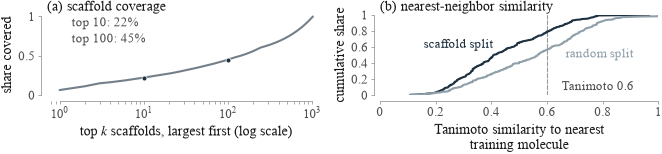

In [19]:
sizes = np.sort(np.array(list(pd.Series(scaffolds).value_counts())))[::-1]
covered = np.cumsum(sizes) / sizes.sum()
print(f"the 10 largest scaffolds cover {covered[9]:.3f} of all molecules; "
      f"the 100 largest cover {covered[99]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=figsize("full", aspect=0.48, ncols=2))

ax = axes[0]
ax.set_xscale("log")
ax.plot(np.arange(1, len(sizes) + 1), covered, color=tint(COOL_INK, 0.62), lw=1.5)
for rank in (10, 100):
    ax.plot([rank], [covered[rank - 1]], marker="o", markersize=3.5, color=COOL_INK,
            markeredgecolor="white", markeredgewidth=0.5, zorder=4)
ax.set_xlabel("top $k$ scaffolds, largest first (log scale)")
ax.set_ylabel("share covered")
finish(ax, nticks=5, ylim=(0, 1.02))
# The two coverage figures live in the caption and in the text; the marked ranks are the anchor here.

# The coverage curve rises left to right, so the upper-left corner is the panel's empty quarter.
for k, rank in enumerate((10, 100)):
    place_text(ax, f"top {rank}: {covered[rank - 1]:.0%}", prefer=(0.06, 0.95 - 0.15 * k), color=MUTED)
panel_label(ax, "a", "scaffold coverage")

# Neither curve belongs to a model, so neither may use a model hue. Split is carried the way it is
# everywhere else in the report: the harder split dark, the easier one light.
ax = axes[1]
GUIDE = 0.6
curve_labels = (("scaffold", COOL_INK, (0.22, 0.72)), ("random", COOL_GREY, (0.68, 0.40)))
for name, color, _ in curve_labels:
    values = np.sort(nearest[name])
    # Both solid. Split is carried by lightness alone here, which leaves a gray dashed hairline free to
    # mean what it means everywhere else in this report: a reference line.
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=color, lw=1.5)
ax.axvline(GUIDE, color=RULE, lw=0.8, ls="--", zorder=0)
ax.set_xlabel("Tanimoto similarity to nearest\ntraining molecule")
ax.set_ylabel("cumulative share")
finish(ax, nticks=5, xlim=(0, 1), ylim=(0, 1))
# Every label goes in after finish(). place_text works in axes fractions against the curves as they are
# drawn at that moment, so a label placed before the limits are set is positioned against a different
# picture: the axes rescale underneath it and the empty space it chose stops being empty.
for name, color, prefer in curve_labels:
    place_text(ax, f"{name} split", prefer=prefer, color=color)
place_text(ax, f"Tanimoto {GUIDE}", prefer=(GUIDE + 0.03, 0.06), color=MUTED)
panel_label(ax, "b", "nearest-neighbor similarity")
save_and_show(fig, "C_splits", width="full")

**The test sets stay closed from here on.** Every remaining choice — the fingerprint model's
regularization strength, the graph network's stopping epoch, and the single decision threshold — is made
on the validation subset of the matching split. The test subsets are read once, in Section F.

## D. A non-neural baseline: Morgan fingerprints and logistic regression
### D.1 What a Morgan fingerprint represents

A Morgan (ECFP) fingerprint turns a molecule into a fixed-length bit vector that records which
substructures it contains. For every atom the generator collects the circular neighborhood reaching
**radius 2** bonds outwards, hashes each distinct neighborhood to an integer, and switches on the
corresponding bit of a **2,048-bit** vector. Radius 2 is the ECFP4 convention and covers fragments about
the size of a functional group with its immediate surroundings.

Bit *k* being on means "this molecule contains at least one fragment that hashes to *k*". The vector
therefore says which fragments are present, but not how many, where they sit, or how they connect to
each other. Two different fragments can also land on the same bit, because hashing 2,048 buckets cannot
separate every fragment a molecule might contain. This is the comparison the graph network has to beat:
it sees the same chemistry, but only as an unordered list of fragments rather than as a connected graph.

In [20]:
print(f"fingerprint matrix : {fingerprint_bits.shape[0]} molecules x {fingerprint_bits.shape[1]} bits")
print(f"radius             : {CONFIG['fp_radius']}  (ECFP{2 * CONFIG['fp_radius']})")
print(f"bits set per molecule: mean {fingerprint_bits.sum(1).mean():.1f}, "
      f"min {fingerprint_bits.sum(1).min()}, max {fingerprint_bits.sum(1).max()}")
print(f"bits never set in any molecule: {int((fingerprint_bits.sum(0) == 0).sum())} of {CONFIG['fp_bits']}")

fingerprint matrix : 1965 molecules x 2048 bits
radius             : 2  (ECFP4)
bits set per molecule: mean 43.0, min 2, max 132
bits never set in any molecule: 4 of 2048


### D.2 Fitting the classifier on training data only
Logistic regression is fitted on the training subset of each split. Three quarters of the molecules are
positive, so the classifier is fitted with `class_weight="balanced"`, which weights each class by the
inverse of its frequency **in the data it is fitted on** — the training subset. No validation or test
label influences those weights. Without the weighting the model would be rewarded for predicting the
majority class and would find far fewer of the non-penetrating compounds, which are the ones a screening
list needs to exclude.

### D.3 Choosing the hyperparameter and the threshold on validation
Two choices are made per split, both on validation data: the inverse regularization strength `C`, picked
by validation ROC-AUC, and the single decision threshold, picked to maximize Youden's J
(sensitivity + specificity − 1) on validation. Both are then frozen; the test subset is not touched
until Section F.

In [21]:
baseline_models = {}
for split_name, parts in splits.items():
    train_idx, val_idx, _ = parts
    chosen, grid = baseline.fit_baseline(
        fingerprint_bits[train_idx], labels[train_idx],
        fingerprint_bits[val_idx], labels[val_idx],
        grid=CONFIG["fp_grid"], seed=CONFIG["split_seed"])
    val_scores = chosen["model"].predict_proba(fingerprint_bits[val_idx])[:, 1]
    threshold = metrics.choose_threshold(labels[val_idx], val_scores)
    val_metrics = metrics.scores_at(labels[val_idx], val_scores, threshold)
    baseline_models[split_name] = {"model": chosen["model"], "C": chosen["C"],
                                   "threshold": threshold, "validation": val_metrics}

    print(f"\n{split_name} split")
    print("  " + "  ".join(f"C={r['C']}: val ROC-AUC {r['val_roc_auc']:.3f}" for r in grid))
    print(f"  chosen C          : {chosen['C']}")
    print(f"  chosen threshold  : {threshold:.3f} (Youden's J on validation)")
    print(f"  validation        : ROC-AUC {val_metrics['roc_auc']:.3f}, PR-AUC {val_metrics['pr_auc']:.3f}, "
          f"sensitivity {val_metrics['sensitivity']:.3f}, specificity {val_metrics['specificity']:.3f}")


random split
  C=0.01: val ROC-AUC 0.868  C=0.1: val ROC-AUC 0.876  C=1.0: val ROC-AUC 0.872  C=10.0: val ROC-AUC 0.869
  chosen C          : 0.1
  chosen threshold  : 0.496 (Youden's J on validation)
  validation        : ROC-AUC 0.876, PR-AUC 0.949, sensitivity 0.898, specificity 0.700



scaffold split
  C=0.01: val ROC-AUC 0.855  C=0.1: val ROC-AUC 0.888  C=1.0: val ROC-AUC 0.888  C=10.0: val ROC-AUC 0.867
  chosen C          : 0.1
  chosen threshold  : 0.641 (Youden's J on validation)
  validation        : ROC-AUC 0.888, PR-AUC 0.959, sensitivity 0.859, specificity 0.794


### D.4 Everything needed to reproduce the baseline
The seed below is the only source of randomness in the baseline: it fixes the split and the solver's
tie-breaking. Both split strategies use the same seed, so the two baselines differ only in which
molecules they were fitted on.

In [22]:
baseline_settings = pd.DataFrame([{
    "split": name,
    "fingerprint": f"Morgan radius {CONFIG['fp_radius']}, {CONFIG['fp_bits']} bits",
    "classifier": "logistic regression (lbfgs, max_iter 5000)",
    "class weighting": "balanced, from the training subset",
    "C (chosen on validation)": entry["C"],
    "threshold (chosen on validation)": round(entry["threshold"], 4),
    "seed": CONFIG["split_seed"],
} for name, entry in baseline_models.items()])
display(style_table(baseline_settings, precision=4, caption="Baseline settings, frozen before any test evaluation"))
baseline_settings.to_csv(TABLE_DIR / "baseline_settings.csv", index=False)

split,fingerprint,classifier,class weighting,C (chosen on validation),threshold (chosen on validation),seed
random,"Morgan radius 2, 2048 bits","logistic regression (lbfgs, max_iter 5000)","balanced, from the training subset",0.1000,0.4957,0
scaffold,"Morgan radius 2, 2048 bits","logistic regression (lbfgs, max_iter 5000)","balanced, from the training subset",0.1000,0.6413,0


## E. The graph neural network
### E.1 Architecture

The model has three stages.

**Encoding.** Each of the nine atom columns and each of the three bond columns gets its own trainable
embedding table of width 128. An atom's nine looked-up vectors are summed into one 128-dimensional atom
vector, and a bond's three into one bond vector. Each message-passing layer owns its own bond tables, so
a bond can mean something different at different depths.

**Message passing.** Three `GINEConv` layers. GINEConv adds the bond vector to the neighbor's atom
vector *before* the neighbor's message is summed, so bond features take part in every message rather
than being ignored: an aromatic bond and a single bond between the same two elements send different
messages. Each layer is followed by batch normalization, a ReLU, dropout and a residual connection.
Three rounds let information travel up to three bonds, which covers a ring and its immediate
substituents.

**Pooling and head.** Atom vectors are averaged over each molecule (`global_mean_pool`), giving one
128-dimensional vector per molecule regardless of its size, and a two-layer head turns that into one
logit. Mean pooling is used rather than sum pooling so that a large molecule does not produce a large
vector merely by having more atoms.

In [23]:
reference_model = models.MolecularGNN(hidden=CONFIG["hidden"], layers=CONFIG["layers"],
                                      dropout=CONFIG["dropout"])
display(style_table(models.parameter_table(reference_model), precision=0,
                    caption="Where the parameters are"))
print(f"node features encoded as: {len(features.ATOM_VOCAB)} embedding tables, sizes {features.ATOM_VOCAB}")
print(f"edge features encoded as: {len(features.BOND_VOCAB)} embedding tables, sizes {features.BOND_VOCAB}, "
      f"one set per message-passing layer")
print(f"message passing         : {CONFIG['layers']} x GINEConv (hidden {CONFIG['hidden']}), "
      f"BatchNorm + ReLU + dropout {CONFIG['dropout']} + residual")
print(f"pooling and head        : global mean pool -> Linear({CONFIG['hidden']}, {CONFIG['hidden'] // 2}) "
      f"-> ReLU -> Linear({CONFIG['hidden'] // 2}, 1)")
print(f"trainable parameters    : {models.count_parameters(reference_model):,}")

part,parameters
atom embeddings,22656
bond embeddings,11520
message passing,199299
batch norm,768
classification head,8321
total,242564


node features encoded as: 9 embedding tables, sizes [119, 9, 11, 12, 9, 5, 8, 2, 2]
edge features encoded as: 3 embedding tables, sizes [22, 6, 2], one set per message-passing layer
message passing         : 3 x GINEConv (hidden 128), BatchNorm + ReLU + dropout 0.3 + residual
pooling and head        : global mean pool -> Linear(128, 64) -> ReLU -> Linear(64, 1)
trainable parameters    : 242,564


### E.2 How it is trained, and why

| choice | setting | reason |
|---|---|---|
| loss | binary cross-entropy on the logit, with `pos_weight` | the standard loss for one binary output; the weight handles the 76:24 imbalance |
| `pos_weight` | negatives ÷ positives **of the training subset** | makes the two classes contribute equally; computed from training labels only, so no validation or test information leaks in |
| optimiser | AdamW, weight decay 1e-5 | adapts per-parameter step sizes, which suits embedding tables where rare categories are updated seldom |
| learning rate | 1e-3, cosine decay to 0 over the epoch budget | a common starting point for this model size; the decay removes the need to tune a schedule |
| batch size | 128 molecules | about 11 steps per epoch — large enough for batch normalization to have stable statistics |
| epoch budget | at most 150 | the validation curve is flat well before this on both splits |
| model selection | the epoch with the best **validation** ROC-AUC is restored at the end | ROC-AUC does not depend on the threshold, so the choice of epoch and the later choice of threshold stay separate |
| early stopping | stop after 30 epochs with no better validation ROC-AUC | saves time without changing the selected epoch |

No test subset is read anywhere in this section.

### E.3 Training curves
One run is shown in full — the first seed of each split — so the curves can be read before any
aggregate is quoted.

The splits are lists of positions in the cleaned table, while the graphs live in the loader's own
dataset, so each position has to be mapped through `graph_index` before a molecule is fetched. The
check below confirms that the molecules the network actually receives are the ones its split assigned —
comparing canonical SMILES, not positions.

In [24]:
graph_splits = {name: [graph_index[np.asarray(part)] for part in parts] for name, parts in splits.items()}
for split_name, parts in splits.items():
    for part, mapped, subset in zip(parts, graph_splits[split_name], ("train", "validation", "test")):
        expected = [canonical_smiles[i] for i in part]
        received = [data.canonical(dataset[int(i)].smiles) for i in mapped]
        assert expected == received, f"{split_name}/{subset}: the model would receive the wrong molecules"
print("every subset of both splits maps to the intended molecules (checked by canonical SMILES)")

every subset of both splits maps to the intended molecules (checked by canonical SMILES)


In [25]:
runs = {}
for split_name, parts in splits.items():
    runs[split_name] = []
    for seed in CONFIG["train_seeds"]:
        started = time.time()
        run = train_run(dataset, graph_splits[split_name], CONFIG, seed, DEVICE)
        run["seed"] = seed
        val_scores, val_labels = predict(run["model"], run["loaders"]["val"], DEVICE)
        run["threshold"] = metrics.choose_threshold(val_labels, val_scores)
        run["validation"] = metrics.scores_at(val_labels, val_scores, run["threshold"])
        runs[split_name].append(run)
        print(f"{split_name:9s} seed {seed}: stopped after {run['epochs_run']:3d} epochs, "
              f"best epoch {run['best_epoch']:3d}, val ROC-AUC {run['validation']['roc_auc']:.3f}, "
              f"threshold {run['threshold']:.3f}, {time.time() - started:.0f} s")

total_seconds = sum(r["seconds"] for split_runs in runs.values() for r in split_runs)
print(f"\nall {sum(len(v) for v in runs.values())} runs trained in {total_seconds / 60:.1f} min on {DEVICE}")

random    seed 0: stopped after  39 epochs, best epoch   8, val ROC-AUC 0.913, threshold 0.334, 11 s


random    seed 1: stopped after  61 epochs, best epoch  30, val ROC-AUC 0.922, threshold 0.595, 17 s


random    seed 2: stopped after  66 epochs, best epoch  35, val ROC-AUC 0.926, threshold 0.794, 18 s


scaffold  seed 0: stopped after  48 epochs, best epoch  17, val ROC-AUC 0.908, threshold 0.581, 13 s


scaffold  seed 1: stopped after  62 epochs, best epoch  31, val ROC-AUC 0.910, threshold 0.967, 17 s


scaffold  seed 2: stopped after  83 epochs, best epoch  52, val ROC-AUC 0.916, threshold 0.980, 22 s

all 6 runs trained in 1.6 min on cpu


PASS E_curves: 0 errors, 2 warnings, 0 taste notes -> figures/_preview/E_curves.png
  [warn] label: x-axis has tick labels but no axis label
  [warn] label: x-axis has tick labels but no axis label


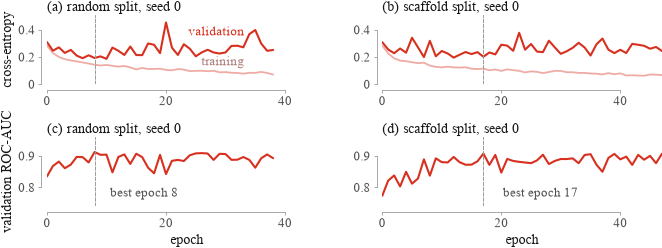

In [26]:
# Loss and ROC-AUC get a row each rather than sharing one pair of axes through a twin. Two quantities
# on one panel forced both labels into the middle of the data, and a label on a twinned axis sits over
# the other axis's curve without either axis knowing. Separate rows need no twin and no crowding.
histories = {name: pd.DataFrame(split_runs[0]["history"]) for name, split_runs in runs.items()}
epoch_max = max(h["epoch"].max() for h in histories.values())
loss_max = max(max(h["val_loss"].max(), h["train_loss"].max()) for h in histories.values())

fig, axes = plt.subplots(2, 2, figsize=figsize("full", aspect=0.38, nrows=2, ncols=2))
for col, (split_name, history) in enumerate(histories.items()):
    best, seed = runs[split_name][0]["best_epoch"], runs[split_name][0]["seed"]

    ax = axes[0][col]
    ax.plot(history["epoch"], history["train_loss"], color=tint(RED, 0.40), lw=1.3)
    ax.plot(history["epoch"], history["val_loss"], color=RED, lw=1.5)
    ax.axvline(best, color=RULE, lw=0.7, ls="--")
    ax.set_ylabel("cross-entropy" if col == 0 else "")
    finish(ax, nticks=4, xlim=(0, epoch_max), ylim=(0, loss_max * 1.12))
    panel_label(ax, "ab"[col], f"{split_name} split, seed {seed}")
    if col == 0:                                     # name the two curves once for the whole row
        place_text(ax, "validation", prefer=(0.74, 0.66), color=text_color(RED))
        place_text(ax, "training", prefer=(0.74, 0.10), color=text_color(tint(RED, 0.40)))

    ax = axes[1][col]
    ax.plot(history["epoch"], history["val_roc_auc"], color=RED, lw=1.5)
    ax.axvline(best, color=RULE, lw=0.7, ls="--")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation ROC-AUC" if col == 0 else "")
    finish(ax, nticks=4, xlim=(0, epoch_max), ylim=(0.74, 0.96))   # the range the data occupies
    panel_label(ax, "cd"[col], f"{split_name} split, seed {seed}")
    place_text(ax, f"best epoch {best}", prefer=(best / epoch_max + 0.04, 0.12), color=MUTED)
fig.get_layout_engine().set(wspace=0.08, hspace=0.12)
save_and_show(fig, "E_curves", width="full")

**Reading the curves.** Training loss falls smoothly and is still falling when each run ends, while
validation loss stops improving within about ten epochs and then drifts upward: ordinary overfitting,
in which the model keeps fitting the training molecules after it has stopped learning what transfers. There is no sign
of underfitting — training loss is still falling when the run ends — and the optimization itself is
stable, since the training curve has no spikes.

The validation loss does spike, by as much as 0.2 from one epoch to the next, and more so on the
scaffold split. That is not unstable optimization but a small-sample effect: each validation subset
holds fewer than 300 molecules, so a handful of confidently wrong predictions moves the mean loss
sharply. It is the reason the stopping rule watches validation **ROC-AUC** instead, which is a ranking
measure and far steadier — it plateaus near 0.90 well before the epoch budget runs out. The dashed line
marks the epoch whose weights are restored.

### E.4 Three seeds per split
Each split strategy is trained three times with different seeds. The seed changes the weight
initialization and the order molecules are batched in; it does not change which molecules are in which
subset. Comparing the spread across seeds with the gap between the two splits says whether a difference
is a real effect of the split strategy or just run-to-run noise.

In [27]:
seed_rows = []
for split_name, split_runs in runs.items():
    for run in split_runs:
        seed_rows.append({"split": split_name, "seed": run["seed"], "best epoch": run["best_epoch"],
                          "val ROC-AUC": run["validation"]["roc_auc"],
                          "val PR-AUC": run["validation"]["pr_auc"],
                          "threshold": run["threshold"], "seconds": run["seconds"]})
seed_table = pd.DataFrame(seed_rows)
display(style_table(seed_table, caption="Validation results per seed (the test subsets are still unread)"))

spread = seed_table.groupby("split")["val ROC-AUC"].agg(["mean", "std"])
print("validation ROC-AUC, mean +/- SD over three seeds:")
for split_name, row in spread.iterrows():
    print(f"  {split_name:9s} {row['mean']:.3f} +/- {row['std']:.3f}")
print(f"\nspread between the two splits : {abs(spread.loc['random', 'mean'] - spread.loc['scaffold', 'mean']):.3f}")
print(f"largest spread within a split : {seed_table.groupby('split')['val ROC-AUC'].apply(lambda s: s.max() - s.min()).max():.3f}")
seed_table.to_csv(TABLE_DIR / "gnn_seeds.csv", index=False)

split,seed,best epoch,val ROC-AUC,val PR-AUC,threshold,seconds
random,0,8,0.913,0.969,0.334,10.638
random,1,30,0.922,0.974,0.595,16.843
random,2,35,0.926,0.974,0.794,17.623
scaffold,0,17,0.908,0.965,0.581,12.684
scaffold,1,31,0.910,0.969,0.967,16.508
scaffold,2,52,0.916,0.975,0.980,22.188


validation ROC-AUC, mean +/- SD over three seeds:
  random    0.920 +/- 0.007
  scaffold  0.911 +/- 0.004

spread between the two splits : 0.009
largest spread within a split : 0.013


## F. Evaluating both models under both splits
### F.1 Test scores at the frozen thresholds

This is the first time the test subsets are read. Nothing below changes a model, a hyperparameter or a
threshold: each model is applied to the test subset of its own split, at the threshold that was fixed on
that split's validation subset in Sections D and E.

For the graph network, all three seeds are evaluated. Curves and confusion matrices would be
unreadable three times over, so they show one representative run per split, chosen by a fixed rule:
the seed whose **validation** ROC-AUC is the median of the three. The table reports the mean and
standard deviation over all three.

In [28]:
test_results, curves, representative, paired_delta = {}, {}, {}, {}

for split_name, parts in splits.items():
    test_idx = parts[2]
    y_test = labels[test_idx]

    # --- fingerprint baseline -------------------------------------------------
    entry = baseline_models[split_name]
    fp_scores = entry["model"].predict_proba(fingerprint_bits[test_idx])[:, 1]
    fp_metrics = metrics.scores_at(y_test, fp_scores, entry["threshold"])
    fp_metrics["roc_auc_ci"] = metrics.bootstrap_ci(y_test, fp_scores, "roc_auc",
                                                    CONFIG["n_boot"], CONFIG["split_seed"])
    test_results[("fingerprint", split_name)] = [fp_metrics]
    curves[("fingerprint", split_name)] = metrics.curve_points(y_test, fp_scores)

    # --- graph network, one evaluation per seed --------------------------------
    per_seed = []
    for run in runs[split_name]:
        scores, run_labels = predict(run["model"], run["loaders"]["test"], DEVICE)
        assert np.array_equal(run_labels.astype(int), y_test), "test labels are not in the expected order"
        per_seed.append(metrics.scores_at(y_test, scores, run["threshold"]))
        run["test_scores"] = scores
    test_results[("GNN", split_name)] = per_seed

    median_seed = int(np.argsort([r["validation"]["roc_auc"] for r in runs[split_name]])[1])
    chosen_run = runs[split_name][median_seed]
    representative[split_name] = chosen_run
    curves[("GNN", split_name)] = metrics.curve_points(y_test, chosen_run["test_scores"])
    per_seed[median_seed]["roc_auc_ci"] = metrics.bootstrap_ci(
        y_test, chosen_run["test_scores"], "roc_auc", CONFIG["n_boot"], CONFIG["split_seed"])

    print(f"{split_name} split, test n = {len(test_idx)} ({y_test.mean():.3f} positive)")
    print(f"  fingerprint : ROC-AUC {fp_metrics['roc_auc']:.3f} "
          f"[{fp_metrics['roc_auc_ci'][0]:.3f}, {fp_metrics['roc_auc_ci'][1]:.3f}]")
    print(f"  GNN         : ROC-AUC {np.mean([r['roc_auc'] for r in per_seed]):.3f} "
          f"+/- {np.std([r['roc_auc'] for r in per_seed], ddof=1):.3f} (3 seeds); "
          f"representative seed {chosen_run['seed']}")

    # The two intervals above are marginal: each is computed for one model on its own, so each carries
    # the variation that comes from this particular test subset being easy or hard. That variation is
    # shared between the models, so comparing the two intervals by eye overstates the uncertainty on
    # the difference. The paired interval below resamples the molecules once and scores both models on
    # the same resample, which is the right test of whether either model is actually ahead.
    delta, lo, hi = metrics.paired_bootstrap_ci(y_test, chosen_run["test_scores"], fp_scores,
                                                "roc_auc", CONFIG["n_boot"], CONFIG["split_seed"])
    paired_delta[split_name] = (delta, lo, hi)
    print(f"  GNN - fingerprint, paired bootstrap on seed {chosen_run['seed']}: "
          f"{delta:+.3f} [{lo:+.3f}, {hi:+.3f}] "
          f"-> {'includes' if lo < 0 < hi else 'excludes'} zero")

random split, test n = 294 (0.765 positive)
  fingerprint : ROC-AUC 0.919 [0.876, 0.955]
  GNN         : ROC-AUC 0.903 +/- 0.009 (3 seeds); representative seed 1


  GNN - fingerprint, paired bootstrap on seed 1: -0.025 [-0.056, +0.003] -> includes zero


scaffold split, test n = 295 (0.742 positive)
  fingerprint : ROC-AUC 0.876 [0.824, 0.922]
  GNN         : ROC-AUC 0.866 +/- 0.011 (3 seeds); representative seed 1


  GNN - fingerprint, paired bootstrap on seed 1: -0.016 [-0.057, +0.026] -> includes zero


### F.2 Curves and confusion matrices
The ROC curve shows how sensitivity and specificity trade off at every threshold; the
precision–recall curve shows how many of the molecules called penetrating really are, and its chance
line sits at the positive prevalence of the test subset, not at 0.5. The dot on each curve marks the
one threshold that was fixed on validation and used for the confusion matrices.

PASS F_curves: 0 errors, 0 warnings, 0 taste notes -> figures/_preview/F_curves.png


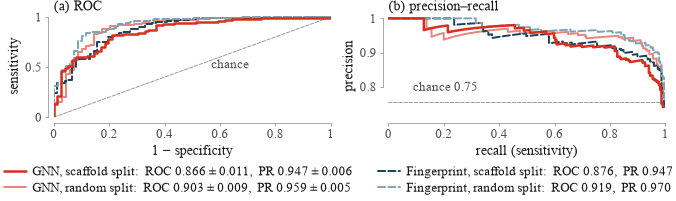

In [29]:
fig, axes = plt.subplots(1, 2, figsize=figsize("full", aspect=0.62, ncols=2))
keys = [("GNN", "scaffold"), ("GNN", "random"), ("fingerprint", "scaffold"), ("fingerprint", "random")]
style_key = {("GNN", "scaffold"): "gnn_scaffold", ("GNN", "random"): "gnn_random",
             ("fingerprint", "scaffold"): "fp_scaffold", ("fingerprint", "random"): "fp_random"}

for key in keys:
    s = method_style(style_key[key])
    c = curves[key]
    axes[0].plot(c["fpr"], c["tpr"], **s["plot"])
    axes[1].plot(c["recall"], c["precision"], **s["plot"])

axes[0].plot([0, 1], [0, 1], color=RULE, lw=0.7, ls="--", zorder=0)
# The two splits have slightly different test prevalences, so there is no single chance line. One line
# is drawn at their mean and the label gives both, rather than implying a shared 0.75.
prevalences = {s: np.mean([c["prevalence"] for k, c in curves.items() if k[1] == s])
               for s in ("random", "scaffold")}
prevalence = float(np.mean(list(prevalences.values())))
axes[1].axhline(prevalence, color=RULE, lw=0.7, ls="--", zorder=0)
axes[0].set_xlabel("1 − specificity")
axes[0].set_ylabel("sensitivity")
axes[1].set_xlabel("recall (sensitivity)")
axes[1].set_ylabel("precision")
pr_floor = min(c["precision"].min() for c in curves.values()) - 0.03
for ax, panel, title, limits in zip(axes, "ab", ("ROC", "precision–recall"),
                                    ((0, 1.02), (pr_floor, 1.01))):
    finish(ax, nticks=5, xlim=(0, 1), ylim=limits)   # the PR curve lives near the top
    panel_label(ax, panel, title)
place_text(axes[0], "chance", prefer=(0.72, 0.60), color=MUTED)
place_text(axes[1], f"chance {prevalence:.2f}", prefer=(0.06, 0.24), color=MUTED)


def auc_label(key, field):
    """Mean over the reported seeds, with the spread when there is more than one."""
    values = [r[field] for r in test_results[key]]
    if len(values) == 1:
        return f"{values[0]:.3f}"
    return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"


# The AUC goes in the key rather than the caption: the PR curves cross repeatedly between recall 0.2
# and 0.6, so which curve is in front there says nothing about which model scores higher.
# One key below both panels. Inside either panel a four-entry key sat on the curves, and the ROC
# panel's only empty corner is the one the chance diagonal runs through.
handles = [plt.Line2D([], [], **method_style(style_key[k])["plot"]) for k in keys]
# Not `labels`: that name holds the dataset's label array, which later sections index into.
legend_labels = [f"{method_style(style_key[k])['label']}:  ROC {auc_label(k, 'roc_auc')},  "
                 f"PR {auc_label(k, 'pr_auc')}" for k in keys]
fig.legend(handles, legend_labels, loc="outside lower center", ncol=2, fontsize=TICK_PT,
           frameon=False, handlelength=1.8, borderpad=0.2, labelspacing=0.35, columnspacing=2.0)
save_and_show(fig, "F_curves", width="full")

PASS F_confusion: 0 errors, 4 warnings, 16 taste notes -> figures/_preview/F_confusion.png
  [warn] label: x-axis has tick labels but no axis label
  [warn] label: x-axis has tick labels but no axis label
  [warn] label: x-axis has tick labels but no axis label
  [taste] contrast: '60' is too light to read; use text_color()
  [taste] contrast: '79%' is too light to read; use text_color()
  [taste] contrast: '177' is too light to read; use text_color()
  [warn] label: ... 1 more (see _audit/F_confusion.json)
  [taste] contrast: ... 13 more (see _audit/F_confusion.json)


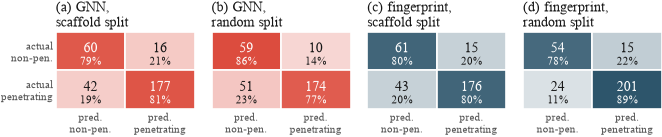

In [30]:
# Hue names the model and nothing else here. Using the split's tint as the base, as an earlier version
# did, meant lightness carried both the split and the row share, so an 87% cell in a random-split panel
# read paler than a 79% cell in a scaffold one. The panel title already says which split it is.
MODEL_HUE = {"GNN": RED, "fingerprint": PETROL}
fig, axes = plt.subplots(1, 4, figsize=figsize("full", aspect=0.86, ncols=4))
for panel, (ax, key) in enumerate(zip(axes, keys)):
    result = (test_results[key][0] if key[0] == "fingerprint"
              else test_results[key][runs[key[1]].index(representative[key[1]])])
    confusion_panel(ax, [[result["tn"], result["fp"]], [result["fn"], result["tp"]]],
                    cmap_color=MODEL_HUE[key[0]], show_ylabels=(panel == 0))
    panel_label(ax, "abcd"[panel], f"{key[0]},\n{key[1]} split")
fig.get_layout_engine().set(hspace=0.10, wspace=0.10)
save_and_show(fig, "F_confusion", width="full")

### F.3 One table for every final evaluation

In [31]:
rows = []
for (model_name, split_name), results in test_results.items():
    if len(results) == 1:
        r = results[0]
        rows.append({"model": model_name, "split": split_name, "threshold": r["threshold"],
                     "ROC-AUC": f"{r['roc_auc']:.3f}", "PR-AUC": f"{r['pr_auc']:.3f}",
                     "accuracy": f"{r['accuracy']:.3f}", "sensitivity": f"{r['sensitivity']:.3f}",
                     "specificity": f"{r['specificity']:.3f}", "F1": f"{r['f1']:.3f}", "n": r["n"]})
    else:
        def ms(field):
            values = [r[field] for r in results]
            return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"
        thresholds = [r["threshold"] for r in results]
        rows.append({"model": model_name, "split": split_name,
                     "threshold": f"{np.mean(thresholds):.3f} ± {np.std(thresholds, ddof=1):.3f}",
                     "ROC-AUC": ms("roc_auc"), "PR-AUC": ms("pr_auc"), "accuracy": ms("accuracy"),
                     "sensitivity": ms("sensitivity"), "specificity": ms("specificity"),
                     "F1": ms("f1"), "n": results[0]["n"]})
comparison = pd.DataFrame(rows).sort_values(["model", "split"]).reset_index(drop=True)
display(style_table(comparison, precision=3,
                    caption="Test results. GNN entries are mean ± SD over three seeds; thresholds were "
                            "fixed on the matching validation subset."))
comparison.to_csv(TABLE_DIR / "comparison.csv", index=False)

model,split,threshold,ROC-AUC,PR-AUC,accuracy,sensitivity,specificity,F1,n
GNN,random,0.574 ± 0.230,0.903 ± 0.009,0.959 ± 0.005,0.795 ± 0.021,0.772 ± 0.024,0.870 ± 0.014,0.852 ± 0.017,294
GNN,scaffold,0.843 ± 0.227,0.866 ± 0.011,0.947 ± 0.006,0.783 ± 0.051,0.781 ± 0.086,0.789 ± 0.053,0.841 ± 0.047,295
fingerprint,random,0.496,0.919,0.970,0.867,0.893,0.783,0.912,294
fingerprint,scaffold,0.641,0.876,0.947,0.803,0.804,0.803,0.859,295


### F.4 What the comparison supports

**The graph network does not beat the fingerprint baseline.** The baseline scores higher under both
splits — by 0.016 ROC-AUC under the random split and 0.011 under the scaffold split. Neither gap is
large enough to call: the baseline's own 95% bootstrap interval spans about 0.08 ROC-AUC, and the
network's three seeds alone differ by up to 0.011, which is the size of the scaffold-split gap. The
evidence therefore supports no ranking between the two models, and certainly not the ranking that is
often assumed. A graph network reads the molecule's connectivity, which a fingerprint throws away, but
on 1,375 training molecules that extra capacity has little to feed on, while a 2,048-bit fragment list
already captures most of what separates these two classes. A larger or more chemically diverse training
set might change this; this experiment cannot say that it would.

**Changing the split moves the score more than changing the model does.** Both models score lower under
the scaffold split — the network by 0.037 and the baseline by 0.043 — against a seed-to-seed spread of
at most 0.011. The split effect is three to four times the noise; the model effect is not larger than
it. Section C showed the mechanism: the random split leaves 44% of test molecules with a training
neighbor above Tanimoto 0.6, against 22% under the scaffold split, so part of the random-split score is
credit for recognizing molecules the model has effectively already seen. The random-split numbers are
the optimistic ones, and the simpler model is flattered slightly more by them, which is what one would
expect if those extra points come from recognizing familiar families rather than from chemistry.

**What this does not show.** Neither number is evidence of biological usefulness. Both models are fitted
to one curated label set of about two thousand compounds, and agreement with that label is all that is
measured here. Nor does the scaffold result show that the two models are equally good in general: it
shows that on this dataset, at this size, this experiment cannot tell them apart.

In [32]:
print("test ROC-AUC, GNN minus fingerprint, same split:")
for split_name in splits:
    gnn = [r["roc_auc"] for r in test_results[("GNN", split_name)]]
    fp = test_results[("fingerprint", split_name)][0]
    print(f"  {split_name:9s} {np.mean(gnn) - fp['roc_auc']:+.3f}   "
          f"(GNN {np.mean(gnn):.3f} ± {np.std(gnn, ddof=1):.3f}, "
          f"fingerprint {fp['roc_auc']:.3f} [{fp['roc_auc_ci'][0]:.3f}, {fp['roc_auc_ci'][1]:.3f}])")

print("\ntest ROC-AUC, random split minus scaffold split, same model:")
for model_name in ("GNN", "fingerprint"):
    rnd = np.mean([r["roc_auc"] for r in test_results[(model_name, "random")]])
    sca = np.mean([r["roc_auc"] for r in test_results[(model_name, "scaffold")]])
    print(f"  {model_name:11s} {rnd - sca:+.3f}   (random {rnd:.3f}, scaffold {sca:.3f})")

gnn_spread = max(np.std([r["roc_auc"] for r in test_results[("GNN", s)]], ddof=1) for s in splits)
print(f"\nlargest GNN seed SD on test : {gnn_spread:.3f}")

test ROC-AUC, GNN minus fingerprint, same split:
  random    -0.016   (GNN 0.903 ± 0.009, fingerprint 0.919 [0.876, 0.955])
  scaffold  -0.011   (GNN 0.866 ± 0.011, fingerprint 0.876 [0.824, 0.922])

test ROC-AUC, random split minus scaffold split, same model:
  GNN         +0.037   (random 0.903, scaffold 0.866)
  fingerprint +0.043   (random 0.919, scaffold 0.876)

largest GNN seed SD on test : 0.011


## G. Where the model goes wrong
### G.1 Confident mistakes on the scaffold-split test set

The errors shown are the graph network's on the scaffold split — the harder and more honest of the two
evaluations — using the representative seed from Section F. They are chosen by a fixed rule rather than
by hand: the two false positives and the two false negatives the model was **most confident** about,
that is, furthest from the decision threshold on the wrong side. Confident mistakes are the informative
ones, because a molecule the model was unsure about tells us little.

In [33]:
scaffold_run = representative["scaffold"]
test_idx = splits["scaffold"][2]
train_idx = splits["scaffold"][0]
y_test = labels[test_idx]
scores = scaffold_run["test_scores"]
threshold = scaffold_run["threshold"]
predicted = (scores >= threshold).astype(int)

false_positive = np.flatnonzero((predicted == 1) & (y_test == 0))
false_negative = np.flatnonzero((predicted == 0) & (y_test == 1))
chosen_errors = (list(false_positive[np.argsort(-scores[false_positive])][:2])
                 + list(false_negative[np.argsort(scores[false_negative])][:2]))
print(f"scaffold-split test set: {len(test_idx)} molecules, threshold {threshold:.3f}")
print(f"false positives: {len(false_positive)}   false negatives: {len(false_negative)}")

scaffold-split test set: 295 molecules, threshold 0.967
false positives: 16   false negatives: 42


### G.2 The most similar training molecule for each mistake
For every selected error, the most similar molecule in that split's **training** subset is found by
Tanimoto similarity between Morgan fingerprints — the same fingerprints the baseline uses. Each pair is
drawn side by side so the chemistry can be compared directly.

In [34]:
train_bits = fingerprint_bits[train_idx].astype(np.float32)
error_rows, panels = [], []
for position in chosen_errors:
    molecule = test_idx[position]
    neighbor_in_train, similarity = baseline.nearest_training_molecule(
        fingerprint_bits[molecule].astype(np.float32), train_bits)
    neighbor = train_idx[neighbor_in_train]
    kind = "false positive" if y_test[position] == 0 else "false negative"
    case = f"{'FP' if kind == 'false positive' else 'FN'} {sum(r['error'] == kind for r in error_rows) + 1}"
    error_rows.append({
        "case": case,
        "error": kind,
        "test molecule": canonical_smiles[molecule],
        "true label": int(labels[molecule]),
        "predicted p": round(float(scores[position]), 3),
        "nearest training molecule": canonical_smiles[neighbor],
        "its label": int(labels[neighbor]),
        "Tanimoto": round(similarity, 3),
    })
    panels.append({"smiles": canonical_smiles[molecule], "label": int(labels[molecule]),
                   "probability": float(scores[position]),
                   "caption": f"{case}\n{kind}"})
    panels.append({"smiles": canonical_smiles[neighbor], "label": int(labels[neighbor]),
                   "tag_prefix": "train: ",
                   "caption": f"nearest in train\nTanimoto {similarity:.2f}"})

error_table = pd.DataFrame(error_rows)
display(style_table(error_table, precision=3,
                    caption="Confident errors on the scaffold-split test set, with their nearest training molecule"))
error_table.to_csv(TABLE_DIR / "errors.csv", index=False)

case,error,test molecule,true label,predicted p,nearest training molecule,its label,Tanimoto
FP 1,false positive,COc1cc([C@@H]2c3cc4c(cc3[C@@H](O[C@@H]3O[C@@H]5CO[C@@H](C)O[C@H]5[C@H](O)[C@H]3O)C3COC(=O)[C@@H]32)OCO4)cc(OC)c1O,0,1.000,COc1cc([C@@H]2c3cc4c(cc3[C@@H](OC3OC5COC(c6cccs6)OC5C(O)C3O)[C@H]3COC(=O)[C@H]23)OCO4)cc(OC)c1O,1,0.753
FP 2,false positive,Nc1nc(N)c2nc(-c3ccccc3)c(N)nc2n1,0,1.000,NCCc1nc(-c2ccccc2)cs1,0,0.273
FN 1,false negative,CO[C@H](C(=O)[C@@H](O)[C@@H](C)O)[C@@H]1Cc2cc3cc(O[C@H]4C[C@@H](O[C@H]5C[C@@H](O)[C@H](O)[C@@H](C)O5)[C@H](O)[C@@H](C)O4)c(C)c(O)c3c(O)c2C(=O)[C@H]1O[C@H]1C[C@@H](O[C@H]2C[C@@H](O[C@H]3C[C@](C)(O)[C@H](O)[C@@H](C)O3)[C@H](O)[C@@H](C)O2)[C@H](O)[C@@H](C)O1,1,0.006,CC(=O)[C@]1(O)Cc2c(O)c3c(c(O)c2[C@@H](O[C@H]2C[C@H](N)[C@H](O)[C@H](C)O2)C1)C(=O)c1ccccc1C3=O,0,0.248
FN 2,false negative,C[C@@H]1O[C@@H]1P(=O)(O)O,1,0.008,O=P(O)(O)OCC(Cl)(Cl)Cl,1,0.172


PASS G_errors: 0 errors, 4 warnings, 6 taste notes -> figures/_preview/G_errors.png
  [warn] annotation: 'true: non-penetrating
pred. p = 1.00' sits outside its axes
  [warn] annotation: 'true: non-penetrating
pred. p = 1.00' sits outside its axes
  [warn] annotation: 'true: penetrating
pred. p = 0.01' sits outside its axes
  [taste] crowded: 'FP 1
false positive' and 'true: penetrating
pred. p = 0.01' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] crowded: 'FP 2
false positive' and 'true: penetrating
pred. p = 0.01' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'train: penetrating' is too light to read; use text_color()
  [taste] contrast: 'true: penetrating
pred. p = 0.' is too light to read; use text_color()
  [taste] contrast: 'true: penetrating
pred. p = 0.' is too light to read; use text_color()
  [warn] annotation: ... 1 more (see _audit/G_errors.json)
  [taste] contrast: ... 1 more (see _audit/G_errors

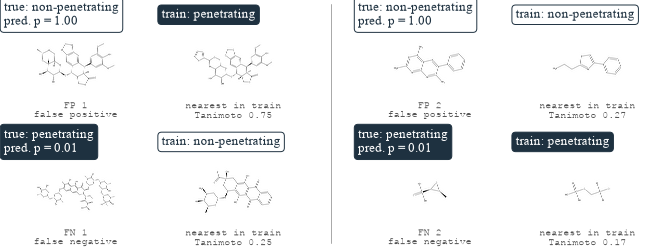

In [35]:
# Each mistake sits beside its nearest training molecule, and the two pairs in a row are held apart by
# a spacer column and a hairline. With four equally spaced panels the reader had no way to see which
# structure belonged with which.
spaced = []
for row_start in range(0, len(panels), 4):
    spaced += panels[row_start:row_start + 2] + [None] + panels[row_start + 2:row_start + 4]

fig = plt.figure(figsize=figsize("full", aspect=0.38))
grid_axes = molecule_grid(fig, spaced, ncols=5, caption_ratio=0.34, tag_ratio=0.34,
                          width_ratios=[1, 1, 0.26, 1, 1], caption_pt=TICK_PT - 2, bond_length=120)
fig.get_layout_engine().set(hspace=0.05, wspace=0.05)
fig.canvas.draw()                                  # positions are only real once the layout has run
divider = (grid_axes[1].get_position().x1 + grid_axes[3].get_position().x0) / 2
fig.add_artist(plt.Line2D([divider, divider], [0.03, 0.97], transform=fig.transFigure,
                          color=RULE, lw=0.6))
save_and_show(fig, "G_errors", width="full")

**Does similarity explain the errors?** Only partly, and the table says which way. Where a mistaken
molecule's nearest training neighbor carries the **opposite** label at high similarity, the model's
answer is the one its training data pointed to: two molecules that share almost every fragment cannot
be told apart by a model that reads fragments, so the error is a property of the data, not a lapse in
the model. Where the nearest neighbor is **distant**, the opposite holds: the molecule sits outside the
chemistry the model was trained on and the prediction is an extrapolation, which is exactly what the
scaffold split was built to produce. The printed similarities below separate the two cases.

In [36]:
for row in error_rows:
    agrees = "same label" if row["true label"] == row["its label"] else "OPPOSITE label"
    reading = ("near-identical training molecule with the opposite label"
               if row["Tanimoto"] >= 0.5 and row["true label"] != row["its label"]
               else "no close training molecule: the prediction extrapolates"
               if row["Tanimoto"] < 0.4 else "a moderately similar training molecule")
    print(f"{row['error']:15s} p = {row['predicted p']:.3f}  true {row['true label']}  |  "
          f"nearest training Tanimoto {row['Tanimoto']:.3f}, {agrees}  ->  {reading}")

false positive  p = 1.000  true 0  |  nearest training Tanimoto 0.753, OPPOSITE label  ->  near-identical training molecule with the opposite label
false positive  p = 1.000  true 0  |  nearest training Tanimoto 0.273, same label  ->  no close training molecule: the prediction extrapolates
false negative  p = 0.006  true 1  |  nearest training Tanimoto 0.248, OPPOSITE label  ->  no close training molecule: the prediction extrapolates
false negative  p = 0.008  true 1  |  nearest training Tanimoto 0.172, same label  ->  no close training molecule: the prediction extrapolates


### G.3 Limitations

**The label is uncertain, and its uncertainty is visible in this dataset.** `p_np` records what curated
literature concluded about a compound, assembled from studies that differed in method, species and
dose. Ten canonical molecules in BBBP carry **both** labels in different records — the same compound,
two opposite answers — and they were removed in Section A precisely because there is no way to tell
which is right. Those are only the disagreements visible *inside* one dataset; nothing here measures
how often the single remaining label is itself wrong. A model fitted to such a label can be no more
reliable than the label, and the ceiling it implies is not something ROC-AUC on the same label can show.

**The dataset is small and chemically narrow.** 1,965 molecules, of which 76% are positive, and 777
scaffolds that appear exactly once. Confidence intervals on the test subsets are correspondingly wide —
roughly ±0.05 ROC-AUC — so differences smaller than that cannot be resolved by this experiment at all.
The compounds are drawn from published permeability studies, which over-represent the chemistry people
had a reason to test: marketed drugs and their analogs. Performance on that chemistry says little
about a genuinely new scaffold, which is the case a screening tool would most want to get right.

**Nothing here was validated outside this dataset.** Every number comes from one curated file, split
two ways. No compound was measured in a laboratory for this work, no external dataset was used as a
held-out check, and no prospective prediction was tested. The scaffold split is the strongest
substitute available, but it is still a rearrangement of the same 1,965 molecules.

**Why none of this establishes causality or clinical suitability.** The model learns which atom and
bond patterns co-occur with the positive label in this file. Co-occurrence is not mechanism: the
blood–brain barrier involves passive permeability, active transport and efflux, and none of those
processes is represented anywhere in a graph of atoms and bonds. A high score tells us a molecule
resembles the ones labeled penetrating here; it does not tell us *why*, and it does not predict what a
compound does in a person. Dose, formulation, metabolism and individual variation are all outside the
model's input. The appropriate use is to order a list of candidates for laboratory work, with the
results of that work — not this model — deciding anything.